In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv("dashboard_ready_data.csv")
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['Revenue'] = df['Quantity'] * df['UnitPrice']


In [3]:
order_revenue = df.groupby(['InvoiceNo','InvoiceDate'])['Revenue'].sum().reset_index()

order_revenue['Month'] = order_revenue['InvoiceDate'].dt.month
order_revenue.head()


,InvoiceNo,InvoiceDate,Revenue,Month
0,536365,2010-12-01 08:26:00,139.12,12
1,536366,2010-12-01 08:28:00,22.20,12
2,536367,2010-12-01 08:34:00,278.73,12
3,536368,2010-12-01 08:34:00,70.05,12
4,536369,2010-12-01 08:35:00,17.85,12


In [4]:
high_months = [9,10,11]
low_months = [1,2]

high_group = order_revenue[order_revenue['Month'].isin(high_months)]['Revenue']
low_group = order_revenue[order_revenue['Month'].isin(low_months)]['Revenue']


In [5]:
t_stat, p_value = stats.ttest_ind(high_group, low_group, equal_var=False)

t_stat, p_value


(np.float64(1.2167298397322108), np.float64(0.22378792185505392))

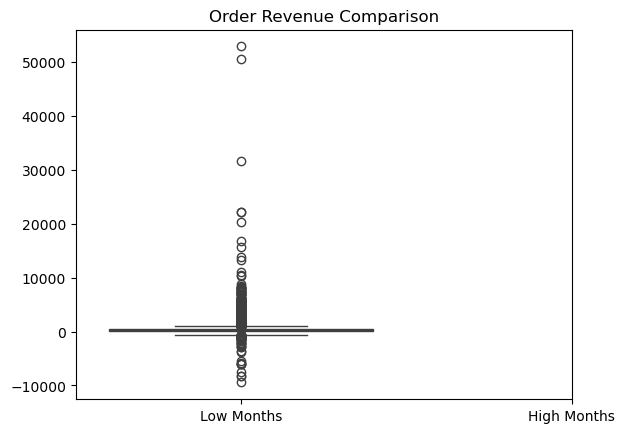

In [6]:
sns.boxplot(data=[low_group, high_group])
plt.xticks([0,1], ['Low Months','High Months'])
plt.title("Order Revenue Comparison")
plt.show()


In [13]:
if p_value < 0.05:
    print("Reject Null Hypothesis: Seasonal months significantly impact order value.")
else:
    print("Fail to Reject Null Hypothesis: No significant difference in order value across seasons.")


Fail to Reject Null Hypothesis: No significant difference in order value across seasons.


In [ ]:
An independent two-sample t-test was conducted to evaluate whether there is a significant difference in average order revenue between high-revenue months (September, October, November) and low-revenue months (January, February).

The test produced a t-statistic of 1.2167 and a p-value of 0.2238. Since the p-value is greater than the significance level of 0.05, we fail to reject the null hypothesis.

This indicates that there is no statistically significant difference in average order value between high-revenue and low-revenue months. Therefore, seasonal increases in total revenue are likely driven by a higher number of transactions rather than a significant increase in individual order value.

From a business perspective, this suggests that revenue growth during peak months is primarily due to increased customer activity rather than customers spending more per order. As a result, strategies focused on customer acquisition and transaction volume may be more impactful than strategies aimed solely at increasing order size.